# Noise-robust LoRA fine-tuning of IndicWhisper (Telugu / Tamil / Hindi)

**Why:** the baseline evaluation showed that accuracy roughly *halves* from clean speech to 0 dB noise
(Telugu 30.8 → 63.9 % WER, Tamil 23.2 → 50.7 %). Meetings are noisy, so this is the weakness worth fixing.

**What this notebook does (the deep-learning contribution):**
1. Loads the per-language IndicWhisper checkpoint (Whisper-medium, ~764 M parameters).
2. Measures the **baseline** on clean speech, white noise (20/10/5/0 dB), babble noise (10/0 dB) and an **unseen** condition (synthetic reverberation).
3. Fine-tunes only **LoRA adapters** (≈ 2 % of the weights) with on-the-fly **noise augmentation** + SpecAugment.
4. Merges the adapter, re-measures under the same conditions, and tests whether the improvement is **statistically significant** (paired bootstrap).
5. Checks the effect on the final **English captions** (chrF against the translation of the gold transcript).
6. Saves the adapter and a merged model for the assistant notebook.

## Data used (and why it is split this way)
`ekacare/vistaar_small_asr_eval` only has a *test* split, so it is divided into three disjoint parts, in the **same shuffled order as the baseline notebook** so the test clips are identical:

| Part | Size | Used for |
|---|---|---|
| **Test** | first 100 clips | final numbers only, never used for training or model selection |
| **Validation** | next 40 clips | choosing the best epoch |
| **Train** | the rest (capped by `MAX_TRAIN`) | LoRA training |

Clips whose text also appears in the test set are removed from train/validation. Noise is synthetic (added on the fly), not a dataset.

**Caveat for your report:** all three parts come from the same source collection, so speakers or recording conditions can overlap between train and test. Report this as a limitation. The checkpoints were also originally trained on data from the same benchmark family, so expect gains mainly in noise robustness, not in new language knowledge.

Before you start: GPU on, Internet on, attach the checkpoint datasets, add the `HF_TOKEN` secret (only needed for the English-caption check).

## 1. Install and patch

In [1]:
!pip install -q "transformers<5" peft jiwer sacrebleu soundfile librosa datasets matplotlib scipy
!pip install -q git+https://github.com/VarunGumma/IndicTransToolkit.git
!pip uninstall -y -q torchao

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import importlib.util, pathlib
try:
    pkg_dir = pathlib.Path(importlib.util.find_spec("IndicTransToolkit").submodule_search_locations[0])
    f = pkg_dir / "collator.py"
    f.write_text(f.read_text().replace(
        "from transformers.tokenization_utils import PreTrainedTokenizerBase",
        "from transformers.tokenization_utils_base import PreTrainedTokenizerBase"))
    print("patched:", f)
except Exception as e:
    print("IndicTransToolkit patch skipped:", repr(e)[:120])

patched: /usr/local/lib/python3.13/dist-packages/IndicTransToolkit/collator.py


## 2. Configuration

In [3]:
import os, re, gc, time, json, math, random, unicodedata, warnings
import numpy as np
import pandas as pd
import torch

warnings.filterwarnings("ignore")
SR = 16000
SEED = 42
OUT = "/kaggle/working/lora_results"
CKPT_OUT = "/kaggle/working/finetuned"
os.makedirs(OUT, exist_ok=True); os.makedirs(CKPT_OUT, exist_ok=True)

LANGS = ["te","ta"]            # start with ONE language to test the run, then use ["te", "ta"] (or add "hi")
LANG_INFO = {
    "hi": dict(name="Hindi",  whisper_lang="hindi",  tag="hin_Deva"),
    "te": dict(name="Telugu", whisper_lang="telugu", tag="tel_Telu"),
    "ta": dict(name="Tamil",  whisper_lang="tamil",  tag="tam_Taml"),
}
MODEL_DIR_OVERRIDE = {}   # e.g. {"te": "/kaggle/input/.../whisper-medium-te_alldata_multigpu"}; otherwise auto-found

ASR_EVAL_REPO = "ekacare/vistaar_small_asr_eval"
N_TEST, N_VAL, MAX_TRAIN = 100, 40, 800     # N_TEST must equal N_ASR of the baseline notebook (100)
MAX_AUDIO_S = 30

# ---- LoRA ----
LORA_R, LORA_ALPHA, LORA_DROPOUT = 32, 64, 0.05
LORA_TARGETS = ["q_proj", "k_proj", "v_proj", "out_proj"]    # attention projections in encoder + decoder
SPEC_AUG = True

# ---- training ----
EPOCHS, BATCH, ACCUM = 3, 4, 2                # effective batch = 8
LR, WARMUP = 3e-4, 20
P_NOISE, SNR_RANGE = 0.7, (0, 20)             # 70 % of training samples get noise at 0-20 dB SNR

# ---- evaluation ----
EVAL_BS = 16
N_NOISE_EVAL = 60                              # clips per noisy condition (clean uses all N_TEST)
CONDITIONS = [("clean", None), ("white", 20), ("white", 10), ("white", 5), ("white", 0),
              ("babble", 10), ("babble", 0), ("reverb", None)]
UNSEEN = {"reverb"}                            # never used in training augmentation
RUN_E2E = True                                 # English caption check (needs HF_TOKEN + IndicTrans2 access)
N_E2E = 40

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32
use_amp = device == "cuda"
print("device:", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "CPU only")

device: cuda | Tesla T4


## 3. Helper functions (text, audio, noise, metrics)

In [4]:
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)


def normalize_text(t):
    if t is None:
        return ""
    t = unicodedata.normalize("NFC", str(t)).replace("‌", "").replace("‍", "")
    t = "".join(" " if unicodedata.category(ch)[0] in ("P", "S") else ch for ch in t)
    return re.sub(r"\s+", " ", t).strip().lower()


def get_audio(a):
    try:
        arr, sr = a["array"], a["sampling_rate"]
    except Exception:
        s = a.get_all_samples()
        arr, sr = s.data.numpy(), s.sample_rate
    arr = np.asarray(arr, dtype=np.float32)
    if arr.ndim > 1:
        arr = arr.mean(axis=0) if arr.shape[0] < arr.shape[-1] else arr.mean(axis=-1)
    if sr != SR:
        import librosa
        arr = librosa.resample(arr, orig_sr=sr, target_sr=SR)
    return arr


def find_whisper_dir(lang):
    if lang in MODEL_DIR_OVERRIDE:
        return MODEL_DIR_OVERRIDE[lang]
    pat = re.compile(rf"whisper-(medium|large)-{lang}[_-]")
    cands = []
    for dp, dn, fn in os.walk("/kaggle/input"):
        if "config.json" in fn and pat.search(os.path.basename(dp)) and \
           any(f.endswith((".bin", ".safetensors")) and f.startswith(("pytorch_model", "model")) for f in fn):
            cands.append(dp)
    if not cands:
        raise FileNotFoundError(f"No checkpoint folder matching whisper-(medium|large)-{lang}_* under /kaggle/input. "
                                f"Attach the dataset or set MODEL_DIR_OVERRIDE['{lang}'].")
    cands.sort(key=lambda p: (0 if "medium" in os.path.basename(p) else 1, p))
    print(f"  checkpoint: {cands[0]}")
    return cands[0]


# ------------------------------- noise -------------------------------
def _scale_to_snr(x, noise, snr_db):
    p = float(np.mean(x ** 2)) + 1e-10
    pn = float(np.mean(noise ** 2)) + 1e-10
    return noise * np.sqrt(p / (10 ** (snr_db / 10)) / pn)


def make_noise(kind, n, rng, pool=None):
    if kind == "white":
        return rng.standard_normal(n).astype(np.float32)
    if kind == "pink":
        X = np.fft.rfft(rng.standard_normal(n))
        f = np.arange(len(X), dtype=np.float64); f[0] = 1.0
        return np.fft.irfft(X / np.sqrt(f), n).astype(np.float32)
    if kind == "babble":
        if not pool:
            return rng.standard_normal(n).astype(np.float32)
        mix = np.zeros(n, dtype=np.float32)
        for _ in range(4):                                   # four overlapping other speakers
            c = pool[int(rng.integers(len(pool)))]
            if len(c) < n:
                c = np.tile(c, int(math.ceil(n / len(c))))
            st = int(rng.integers(0, len(c) - n + 1))
            mix += c[st:st + n] / (np.sqrt(np.mean(c[st:st + n] ** 2)) + 1e-6)
        return mix
    raise ValueError(kind)


def add_noise(x, kind, snr_db, rng, pool=None):
    noise = _scale_to_snr(x, make_noise(kind, len(x), rng, pool), snr_db)
    return np.clip(x + noise, -1.0, 1.0).astype(np.float32)


def add_reverb(x, rng):
    from scipy.signal import fftconvolve
    rt60 = float(rng.uniform(0.3, 0.8))
    t = np.arange(int(SR * rt60)) / SR
    ir = rng.standard_normal(len(t)) * np.exp(-6.9 * t / rt60)
    ir[0] = 1.0                                              # direct path
    ir = ir / np.sqrt(np.sum(ir ** 2))
    y = fftconvolve(x, ir)[:len(x)]
    y = y * (np.sqrt(np.mean(x ** 2)) + 1e-8) / (np.sqrt(np.mean(y ** 2)) + 1e-8)
    return np.clip(y, -1.0, 1.0).astype(np.float32)


def augment_train(x, rng, pool):
    x = x * float(10 ** (rng.uniform(-6, 3) / 20))           # random gain
    if rng.random() < P_NOISE:
        kind = ["white", "pink", "babble"][int(rng.integers(3))]
        x = add_noise(np.clip(x, -1, 1), kind, float(rng.uniform(*SNR_RANGE)), rng, pool)
    return np.clip(x, -1.0, 1.0).astype(np.float32)


def condition_audio(cond, audios, pool, seed):
    kind, snr = cond
    out = []
    for i, x in enumerate(audios):
        rng = np.random.default_rng(seed * 100003 + i)
        if kind == "clean":
            out.append(x)
        elif kind == "reverb":
            out.append(add_reverb(x, rng))
        else:
            out.append(add_noise(x, kind, snr, rng, pool))
    return out


def cond_name(c):
    return c[0] if c[1] is None else f"{c[0]}{c[1]}"


# ------------------------------- metrics -------------------------------
def per_clip_errors(refs, hyps):
    import jiwer
    err, nref = [], []
    for r, h in zip(refs, hyps):
        n = len(r.split())
        if not h.strip():
            err.append(n)
        else:
            o = jiwer.process_words(r, h)
            err.append(o.substitutions + o.deletions + o.insertions)
        nref.append(n)
    return np.array(err, dtype=float), np.array(nref, dtype=float)


def corpus_wer_cer(refs, hyps):
    import jiwer
    e, n = per_clip_errors(refs, hyps)
    hy = [h if h.strip() else "x" for h in hyps]               # jiwer needs non-empty hypothesis for CER
    return 100 * e.sum() / n.sum(), 100 * jiwer.cer(refs, hy)


def paired_bootstrap(err_a, err_b, nref, B=2000, seed=0):
    # difference in corpus WER (b - a) in percentage points, with a 95 % CI, resampling clips
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(nref), size=(B, len(nref)))
    wa = err_a[idx].sum(1) / nref[idx].sum(1)
    wb = err_b[idx].sum(1) / nref[idx].sum(1)
    d = 100 * (wb - wa)
    return float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5))

## 4. Data: test / validation / train split (same order as the baseline notebook)

In [5]:
def load_splits(lang):
    from datasets import load_dataset
    ds = load_dataset(ASR_EVAL_REPO, lang, split="test")
    cols = ds.column_names
    text_col = next(c for c in ("text", "transcription", "sentence", "raw_transcription") if c in cols)
    if "duration" in cols:
        ds = ds.filter(lambda d: 0.5 <= d <= MAX_AUDIO_S, input_columns=["duration"])
    ds = ds.shuffle(seed=SEED)                                # identical to the baseline notebook
    test, val, train, test_texts = [], [], [], set()
    for row in ds:
        ref_n = normalize_text(row[text_col])
        if not ref_n:
            continue
        audio = get_audio(row["audio"])
        dur = len(audio) / SR
        if dur < 0.5 or dur > MAX_AUDIO_S:
            continue
        s = dict(audio=audio, text=row[text_col], text_n=ref_n, duration=dur, source=row.get("source", "unknown"))
        if len(test) < N_TEST:
            test.append(s); test_texts.add(ref_n)
        elif len(val) < N_VAL:
            val.append(s)
        elif MAX_TRAIN is None or len(train) < MAX_TRAIN:
            train.append(s)
        else:
            break
    val = [s for s in val if s["text_n"] not in test_texts]
    train = [s for s in train if s["text_n"] not in test_texts]
    vt = {s["text_n"] for s in val}
    train = [s for s in train if s["text_n"] not in vt]
    return train, val, test


def report_splits(lang, train, val, test):
    rows = []
    for name, d in (("train", train), ("validation", val), ("test", test)):
        rows.append(dict(split=name, clips=len(d), minutes=sum(s["duration"] for s in d) / 60,
                         **{f"src_{k}": v for k, v in pd.Series([s["source"] for s in d]).value_counts().items()}))
    df = pd.DataFrame(rows).fillna(0)
    df.to_csv(os.path.join(OUT, f"{lang}_dataset_split.csv"), index=False)
    display(df.round(1))
    assert not ({s["text_n"] for s in test} & {s["text_n"] for s in train}), "text leakage between train and test!"

## 5. Model loading and batched evaluation

In [6]:
from transformers import WhisperForConditionalGeneration, WhisperFeatureExtractor, WhisperTokenizer


def load_whisper(path):
    fe = WhisperFeatureExtractor.from_pretrained(path)
    tok = WhisperTokenizer.from_pretrained(path)
    model = WhisperForConditionalGeneration.from_pretrained(path, dtype=dtype).to(device)
    model.config.forced_decoder_ids = None
    model.generation_config.forced_decoder_ids = None
    return model, fe, tok


def transcribe_batch(model, fe, tok, audios, lang, bs=EVAL_BS):
    model.eval()
    outs = []
    mdtype = next(model.parameters()).dtype
    for i in range(0, len(audios), bs):
        feats = fe([np.asarray(a, dtype=np.float32) for a in audios[i:i + bs]], sampling_rate=SR,
                   return_tensors="pt").input_features.to(device, mdtype)
        with torch.no_grad(), torch.autocast(device_type=device, dtype=torch.float16, enabled=use_amp):
            ids = model.generate(input_features=feats, language=LANG_INFO[lang]["whisper_lang"],
                                 task="transcribe", max_new_tokens=200, num_beams=1, use_cache=True)
        outs += [t.strip() for t in tok.batch_decode(ids, skip_special_tokens=True)]
    return outs


def evaluate_model(model, fe, tok, lang, test, pool, tag=""):
    res = {}
    refs_all = [s["text_n"] for s in test]
    for ci, cond in enumerate(CONDITIONS):
        n = len(test) if cond[0] == "clean" else min(N_NOISE_EVAL, len(test))
        aud = condition_audio(cond, [s["audio"] for s in test[:n]], pool, SEED + ci)
        hyps_raw = transcribe_batch(model, fe, tok, aud, lang)
        hyps = [normalize_text(h) for h in hyps_raw]
        refs = refs_all[:n]
        err, nref = per_clip_errors(refs, hyps)
        wer, cer = corpus_wer_cer(refs, hyps)
        res[cond_name(cond)] = dict(n=n, wer=wer, cer=cer, err=err, nref=nref, hyps=hyps)
        print(f"  [{tag}] {cond_name(cond):9s} n={n:3d}  WER {wer:5.1f}%  CER {cer:5.1f}%")
    return res

## 6. LoRA training

In [7]:
from peft import LoraConfig, get_peft_model
from transformers import get_linear_schedule_with_warmup


class TrainSet(torch.utils.data.Dataset):
    def __init__(self, samples, pool, fe, tok, seed=0):
        self.s, self.pool, self.fe, self.tok, self.seed, self.epoch = samples, pool, fe, tok, seed, 0

    def __len__(self):
        return len(self.s)

    def __getitem__(self, i):
        rng = np.random.default_rng((self.seed, self.epoch, i))
        x = augment_train(self.s[i]["audio"], rng, self.pool)
        feats = self.fe(x, sampling_rate=SR, return_tensors="np").input_features[0]
        ids = self.tok(self.s[i]["text_n"]).input_ids[:440]
        return feats, ids


def make_collate(start_id):
    def collate(batch):
        feats = torch.tensor(np.stack([b[0] for b in batch]))
        seqs = [b[1][1:] if b[1] and b[1][0] == start_id else b[1] for b in batch]   # model re-adds the start token
        L = max(len(s) for s in seqs)
        labels = torch.full((len(seqs), L), -100, dtype=torch.long)
        for i, s in enumerate(seqs):
            labels[i, :len(s)] = torch.tensor(s)
        return feats, labels
    return collate


def train_lora(model, fe, tok, lang, train, val, pool, tag_dir):
    tok.set_prefix_tokens(language=LANG_INFO[lang]["whisper_lang"], task="transcribe", predict_timestamps=False)
    model.config.use_cache = False
    if SPEC_AUG:
        model.config.apply_spec_augment = True
        model.config.mask_time_prob, model.config.mask_time_length, model.config.mask_feature_prob = 0.05, 10, 0.0
    model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    pm = get_peft_model(model, LoraConfig(r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT,
                                          target_modules=LORA_TARGETS, bias="none"))
    for p in pm.parameters():
        if p.requires_grad:
            p.data = p.data.float()                              # adapters in fp32, frozen base in fp16
    trainable = [p for p in pm.parameters() if p.requires_grad]
    n_tr, n_all = sum(p.numel() for p in trainable), sum(p.numel() for p in pm.parameters())
    print(f"  trainable parameters: {n_tr/1e6:.1f} M of {n_all/1e6:.0f} M ({100*n_tr/n_all:.2f} %)")

    ds = TrainSet(train, pool, fe, tok, seed=SEED)
    loader = torch.utils.data.DataLoader(ds, batch_size=BATCH, shuffle=True,
                                         collate_fn=make_collate(model.config.decoder_start_token_id))
    total = math.ceil(len(loader) / ACCUM) * EPOCHS
    opt = torch.optim.AdamW(trainable, lr=LR, weight_decay=0.01)
    sched = get_linear_schedule_with_warmup(opt, min(WARMUP, total // 5), total)
    scaler = torch.amp.GradScaler(device, enabled=use_amp)
    mdtype = next(model.parameters()).dtype

    val_audio = [s["audio"] for s in val]
    val_noisy = condition_audio(("babble", 5), val_audio, pool, SEED + 777)
    val_refs = [s["text_n"] for s in val]

    def val_score():
        c = corpus_wer_cer(val_refs, [normalize_text(h) for h in transcribe_batch(pm, fe, tok, val_audio, lang)])[0]
        n = corpus_wer_cer(val_refs, [normalize_text(h) for h in transcribe_batch(pm, fe, tok, val_noisy, lang)])[0]
        return c, n, (c + n) / 2

    hist = dict(step=[], loss=[], epoch_val=[])
    best, best_score = None, 1e9
    c0, n0, s0 = val_score()
    print(f"  validation before training: clean {c0:.1f}%  babble5 {n0:.1f}%  mean {s0:.1f}%")
    hist["epoch_val"].append(dict(epoch=0, clean=c0, noisy=n0, score=s0))
    best = {n: p.detach().cpu().clone() for n, p in pm.named_parameters() if p.requires_grad}
    best_score, best_epoch = s0, 0
    step, t0 = 0, time.time()
    if device == "cuda":
        torch.cuda.reset_peak_memory_stats()
    for ep in range(1, EPOCHS + 1):
        ds.epoch = ep
        pm.train(); opt.zero_grad(set_to_none=True)
        for it, (feats, labels) in enumerate(loader):
            feats, labels = feats.to(device, mdtype), labels.to(device)
            with torch.autocast(device_type=device, dtype=torch.float16, enabled=use_amp):
                loss = pm(input_features=feats, labels=labels).loss / ACCUM
            scaler.scale(loss).backward()
            if (it + 1) % ACCUM == 0 or it + 1 == len(loader):
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(trainable, 1.0)
                scaler.step(opt); scaler.update(); sched.step(); opt.zero_grad(set_to_none=True)
                step += 1
                hist["step"].append(step); hist["loss"].append(float(loss.item() * ACCUM))
                if step % 10 == 0:
                    print(f"  epoch {ep} step {step}/{total} loss {np.mean(hist['loss'][-10:]):.3f} "
                          f"({time.time()-t0:.0f}s)")
        c, n, s = val_score()
        hist["epoch_val"].append(dict(epoch=ep, clean=c, noisy=n, score=s))
        print(f"  epoch {ep}: validation clean {c:.1f}%  babble5 {n:.1f}%  mean {s:.1f}%")
        pm.save_pretrained(os.path.join(tag_dir, f"adapter_epoch{ep}"))
        if s < best_score:
            best_score, best_epoch = s, ep
            best = {k: p.detach().cpu().clone() for k, p in pm.named_parameters() if p.requires_grad}
    with torch.no_grad():
        for k, p in pm.named_parameters():
            if k in best:
                p.copy_(best[k].to(p.device))
    print(f"  best epoch: {best_epoch} (validation mean WER {best_score:.1f}%)  train time {time.time()-t0:.0f}s")
    hist["best_epoch"], hist["train_s"] = best_epoch, time.time() - t0
    hist["gpu_peak_gb"] = torch.cuda.max_memory_allocated() / 1024 ** 3 if device == "cuda" else 0.0
    hist["trainable_M"], hist["total_M"] = n_tr / 1e6, n_all / 1e6
    pm.save_pretrained(os.path.join(tag_dir, "adapter_best"))
    merged = pm.merge_and_unload()
    merged.config.use_cache = True
    merged.eval()
    return merged, hist

## 7. English-caption check (optional): does the adapted ASR also give better translations?

In [8]:
translate_batch = None
if RUN_E2E:
    try:
        from kaggle_secrets import UserSecretsClient
        from huggingface_hub import login
        login(token=UserSecretsClient().get_secret("HF_TOKEN"))
        from transformers import AutoModelForSeq2SeqLM, AutoTokenizer
        from IndicTransToolkit.processor import IndicProcessor
        MT_CKPT = "ai4bharat/indictrans2-indic-en-dist-200M"
        mt_tok = AutoTokenizer.from_pretrained(MT_CKPT, trust_remote_code=True)
        mt_model = AutoModelForSeq2SeqLM.from_pretrained(MT_CKPT, trust_remote_code=True, dtype=dtype).to(device).eval()
        ip = IndicProcessor(inference=True)

        def _tr(sents, tag):
            b = ip.preprocess_batch(sents, src_lang=tag, tgt_lang="eng_Latn")
            inp = mt_tok(b, truncation=True, padding="longest", return_tensors="pt", return_attention_mask=True).to(device)
            with torch.no_grad():
                out = mt_model.generate(**inp, use_cache=False, min_length=0, max_length=256, num_beams=5)
            return ip.postprocess_batch(mt_tok.batch_decode(out, skip_special_tokens=True), lang="eng_Latn")

        def translate_batch(texts, tag, bs=8):
            outs = [""] * len(texts)
            idx = [i for i, t in enumerate(texts) if t.strip()]
            for k in range(0, len(idx), bs):
                ci = idx[k:k + bs]
                for i, r in zip(ci, _tr([texts[i] for i in ci], tag)):
                    outs[i] = r
            return outs
        print("IndicTrans2 ready")
    except Exception as e:
        print("English-caption check disabled:", repr(e)[:200])
        translate_batch = None


def e2e_effect(lang, base, lora, test):
    if translate_batch is None:
        return None
    import sacrebleu
    from sacrebleu.metrics import CHRF
    tag = LANG_INFO[lang]["tag"]
    n = min(N_E2E, N_NOISE_EVAL)
    gold = translate_batch([s["text_n"] for s in test[:n]], tag)
    rows = []
    for cname in ("clean", "white5", "babble0"):
        row = dict(condition=cname)
        for nm, r in (("baseline", base), ("lora", lora)):
            en = translate_batch(r[cname]["hyps"][:n], tag)
            row[f"chrF++_{nm}"] = CHRF(word_order=2).corpus_score(en, [gold]).score
            row[f"BLEU_{nm}"] = sacrebleu.corpus_bleu(en, [gold]).score
        rows.append(row)
    return pd.DataFrame(rows)

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenization_indictrans.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/ai4bharat/indictrans2-indic-en-dist-200M:
- tokenization_indictrans.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


dict.SRC.json: 0.00B [00:00, ?B/s]

dict.TGT.json: 0.00B [00:00, ?B/s]

...

modeling_indictrans.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/ai4bharat/indictrans2-indic-en-dist-200M:
- modeling_indictrans.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


model.safetensors:   0%|          | 0.00/913M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/163 [00:00<?, ?B/s]

IndicTrans2 ready


## 8. Run one language end to end (baseline → train → adapted → statistics → plots → save)

Telugu (te)


README.md: 0.00B [00:00, ?B/s]

te/test-00000.parquet:   0%|          | 0.00/149M [00:00<?, ?B/s]

te/test-00001.parquet:   0%|          | 0.00/49.7M [00:00<?, ?B/s]

Generating test split:   0%|          | 0/752 [00:00<?, ? examples/s]

Filter:   0%|          | 0/752 [00:00<?, ? examples/s]

,split,clips,minutes,src_mucs,src_kathbath_noisy,src_kathbath,src_fleurs,src_indictts
0,train,553,74.6,207,95,95,82,74
1,validation,39,4.8,13,9,5,6,6
2,test,100,13.2,34,24,21,12,9


  checkpoint: /kaggle/input/datasets/alwalmedhana/telugu-models/telugu_models/whisper-medium-te_alldata_multigpu
-- baseline evaluation
  [baseline] clean     n=100  WER  37.5%  CER  15.7%
  [baseline] white20   n= 60  WER  36.9%  CER  12.7%
  [baseline] white10   n= 60  WER  46.5%  CER  15.9%
  [baseline] white5    n= 60  WER  54.6%  CER  21.0%
  [baseline] white0    n= 60  WER  70.8%  CER  31.8%
  [baseline] babble10  n= 60  WER  43.0%  CER  15.6%
  [baseline] babble0   n= 60  WER  86.7%  CER  54.0%
  [baseline] reverb    n= 60  WER  57.2%  CER  24.2%
-- LoRA training
  trainable parameters: 18.9 M of 783 M (2.41 %)
  validation before training: clean 29.2%  babble5 53.8%  mean 41.5%
  epoch 1 step 10/210 loss 0.298 (48s)
  epoch 1 step 20/210 loss 0.158 (96s)
  epoch 1 step 30/210 loss 0.180 (144s)
  epoch 1 step 40/210 loss 0.130 (191s)
  epoch 1 step 50/210 loss 0.142 (238s)
  epoch 1 step 60/210 loss 0.118 (286s)
  epoch 1 step 70/210 loss 0.147 (329s)
  epoch 1: validation clean

,condition,unseen,n_clips,WER_baseline,WER_lora,delta_WER_pp,CI95_low,CI95_high,significant,CER_baseline,CER_lora
0,clean,False,100,37.46,36.06,-1.39,-3.36,0.71,no clear change,15.72,15.40
1,white20,False,60,36.94,36.63,-0.31,-3.61,3.09,no clear change,12.66,13.26
2,white10,False,60,46.52,44.05,-2.47,-5.26,0.17,no clear change,15.85,15.55
3,white5,False,60,54.56,49.77,-4.79,-8.26,-1.03,better,20.98,20.70
4,white0,False,60,70.79,67.85,-2.94,-6.43,0.64,no clear change,31.82,33.54
5,babble10,False,60,42.97,43.74,0.77,-2.94,4.69,no clear change,15.61,15.81
6,babble0,False,60,86.71,80.06,-6.65,-11.70,-1.67,better,54.04,47.83
7,reverb,True,60,57.19,55.02,-2.16,-5.56,1.04,no clear change,24.24,25.41


,condition,chrF++_baseline,BLEU_baseline,chrF++_lora,BLEU_lora
0,clean,70.53,53.11,71.72,55.02
1,white5,47.53,23.65,53.77,33.48
2,babble0,30.29,7.10,31.11,10.00


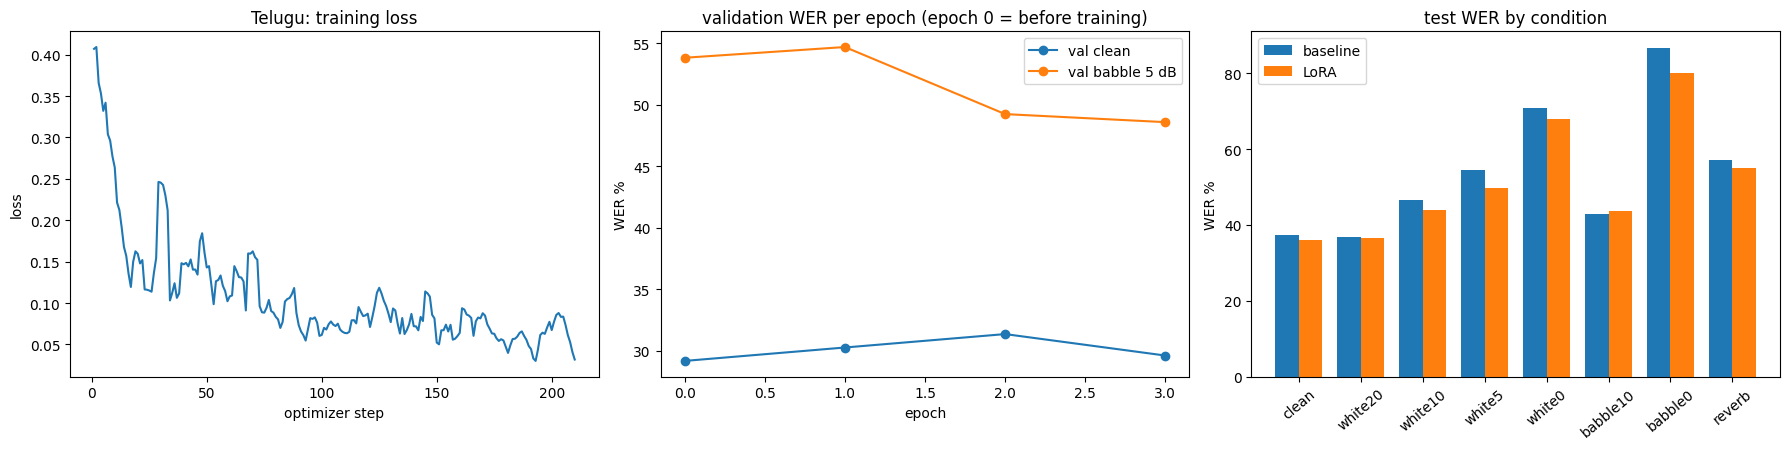

saved merged model -> /kaggle/working/finetuned/te/merged
Tamil (ta)


ta/test-00000.parquet:   0%|          | 0.00/84.1M [00:00<?, ?B/s]

ta/test-00001.parquet:   0%|          | 0.00/136M [00:00<?, ?B/s]

ta/test-00002.parquet:   0%|          | 0.00/73.4M [00:00<?, ?B/s]

Generating test split:   0%|          | 0/1358 [00:00<?, ? examples/s]

Filter:   0%|          | 0/1358 [00:00<?, ? examples/s]

,split,clips,minutes,src_commonvoice,src_mucs,src_kathbath_noisy,src_kathbath,src_fleurs,src_indictts
0,train,779,90.9,332,150,89,87,63,58
1,validation,39,4.3,14,9,4,6,1,5
2,test,100,12.0,43,21,12,9,9,6


  checkpoint: /kaggle/input/datasets/alwalmedhana/tamil-models/tamil_models/whisper-medium-ta_alldata_multigpu
-- baseline evaluation
  [baseline] clean     n=100  WER  25.5%  CER   6.3%
  [baseline] white20   n= 60  WER  28.1%  CER   7.0%
  [baseline] white10   n= 60  WER  36.0%  CER  10.0%
  [baseline] white5    n= 60  WER  41.9%  CER  13.3%
  [baseline] white0    n= 60  WER  52.1%  CER  19.9%
  [baseline] babble10  n= 60  WER  31.9%  CER   9.0%
  [baseline] babble0   n= 60  WER  86.0%  CER  47.3%
  [baseline] reverb    n= 60  WER  41.9%  CER  13.2%
-- LoRA training
  trainable parameters: 18.9 M of 783 M (2.41 %)
  validation before training: clean 25.6%  babble5 49.7%  mean 37.6%
  epoch 1 step 10/294 loss 0.408 (44s)
  epoch 1 step 20/294 loss 0.266 (88s)
  epoch 1 step 30/294 loss 0.266 (132s)
  epoch 1 step 40/294 loss 0.237 (176s)
  epoch 1 step 50/294 loss 0.187 (219s)
  epoch 1 step 60/294 loss 0.221 (263s)
  epoch 1 step 70/294 loss 0.193 (308s)
  epoch 1 step 80/294 loss 0.

,condition,unseen,n_clips,WER_baseline,WER_lora,delta_WER_pp,CI95_low,CI95_high,significant,CER_baseline,CER_lora
0,clean,False,100,25.47,25.86,0.39,-1.83,2.57,no clear change,6.34,6.51
1,white20,False,60,28.08,26.11,-1.97,-5.46,1.28,no clear change,6.95,6.74
2,white10,False,60,35.96,33.83,-2.13,-5.49,1.40,no clear change,9.96,9.64
3,white5,False,60,41.87,38.92,-2.96,-6.36,0.18,no clear change,13.34,12.58
4,white0,False,60,52.05,54.02,1.97,-1.60,5.24,no clear change,19.87,20.64
5,babble10,False,60,31.86,29.89,-1.97,-5.12,1.14,no clear change,9.02,7.59
6,babble0,False,60,86.04,70.94,-15.11,-21.19,-9.67,better,47.28,33.87
7,reverb,True,60,41.87,43.02,1.15,-2.36,5.02,no clear change,13.19,13.90


,condition,chrF++_baseline,BLEU_baseline,chrF++_lora,BLEU_lora
0,clean,74.35,59.09,79.24,68.37
1,white5,62.63,41.81,60.07,41.15
2,babble0,33.36,13.03,37.79,15.79


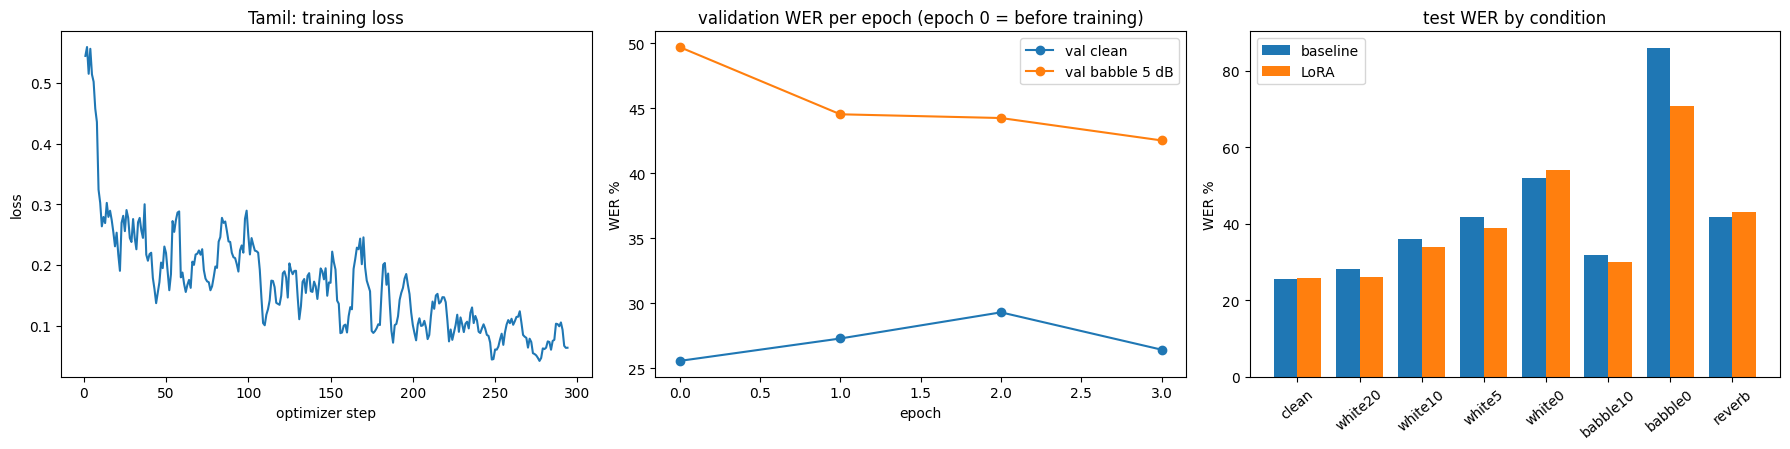

saved merged model -> /kaggle/working/finetuned/ta/merged


In [9]:
import matplotlib.pyplot as plt


def run_language(lang):
    info = LANG_INFO[lang]
    print("=" * 72, f"\n{info['name']} ({lang})")
    set_seed()
    train, val, test = load_splits(lang)
    report_splits(lang, train, val, test)
    pool = [s["audio"] for s in train][:200]
    ldir = os.path.join(CKPT_OUT, lang); os.makedirs(ldir, exist_ok=True)
    rdir = os.path.join(OUT, lang); os.makedirs(rdir, exist_ok=True)

    path = find_whisper_dir(lang)
    model, fe, tok = load_whisper(path)
    print("-- baseline evaluation")
    base = evaluate_model(model, fe, tok, lang, test, pool, tag="baseline")

    print("-- LoRA training")
    merged, hist = train_lora(model, fe, tok, lang, train, val, pool, ldir)

    print("-- adapted evaluation")
    lora = evaluate_model(merged, fe, tok, lang, test, pool, tag="lora")

    rows = []
    for cname in base:
        b, l = base[cname], lora[cname]
        lo, hi = paired_bootstrap(b["err"], l["err"], b["nref"])
        rows.append(dict(condition=cname, unseen=cname in UNSEEN, n_clips=b["n"],
                         WER_baseline=b["wer"], WER_lora=l["wer"], delta_WER_pp=l["wer"] - b["wer"],
                         CI95_low=lo, CI95_high=hi,
                         significant=("better" if hi < 0 else "worse" if lo > 0 else "no clear change"),
                         CER_baseline=b["cer"], CER_lora=l["cer"]))
    table = pd.DataFrame(rows)
    table.to_csv(os.path.join(rdir, "baseline_vs_lora.csv"), index=False)
    display(table.round(2))

    pd.DataFrame(dict(step=hist["step"], loss=hist["loss"])).to_csv(os.path.join(rdir, "train_loss.csv"), index=False)
    pd.DataFrame(hist["epoch_val"]).to_csv(os.path.join(rdir, "val_per_epoch.csv"), index=False)
    pd.DataFrame({cn: dict(base=base[cn]["hyps"][0], lora=lora[cn]["hyps"][0], ref=test[0]["text_n"])
                  for cn in base}).T.to_csv(os.path.join(rdir, "example_transcripts.csv"))

    e2e = e2e_effect(lang, base, lora, test)
    if e2e is not None:
        e2e.to_csv(os.path.join(rdir, "english_caption_effect.csv"), index=False); display(e2e.round(2))

    # plots
    fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
    ls = pd.Series(hist["loss"]).rolling(5, min_periods=1).mean()
    ax[0].plot(hist["step"], ls); ax[0].set(title=f"{info['name']}: training loss", xlabel="optimizer step", ylabel="loss")
    ev = pd.DataFrame(hist["epoch_val"])
    ax[1].plot(ev.epoch, ev.clean, marker="o", label="val clean"); ax[1].plot(ev.epoch, ev.noisy, marker="o", label="val babble 5 dB")
    ax[1].set(title="validation WER per epoch (epoch 0 = before training)", xlabel="epoch", ylabel="WER %"); ax[1].legend()
    x = np.arange(len(table)); w = 0.38
    ax[2].bar(x - w/2, table.WER_baseline, w, label="baseline"); ax[2].bar(x + w/2, table.WER_lora, w, label="LoRA")
    ax[2].set_xticks(x); ax[2].set_xticklabels(table.condition, rotation=40); ax[2].set(title="test WER by condition", ylabel="WER %"); ax[2].legend()
    plt.tight_layout(); plt.savefig(os.path.join(rdir, "plots.png"), dpi=130); plt.show()

    # save merged model for the assistant notebook
    mdir = os.path.join(ldir, "merged")
    merged.save_pretrained(mdir); fe.save_pretrained(mdir); tok.save_pretrained(mdir)
    print("saved merged model ->", mdir)
    hist["table"], hist["e2e"] = table, e2e
    del model, merged
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return hist


RESULTS = {}
for lang in LANGS:
    try:
        RESULTS[lang] = run_language(lang)
    except Exception as e:
        import traceback; traceback.print_exc()
        print(f"!! {lang} failed: {e!r}")
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

## 9. Summary across languages and a zip of everything

In [10]:
import shutil
rows = []
for l, h in RESULTS.items():
    t = h["table"].set_index("condition")
    for cn in ("clean", "white0", "babble0", "reverb"):
        if cn in t.index:
            rows.append(dict(language=LANG_INFO[l]["name"], condition=cn,
                             baseline_WER=t.loc[cn, "WER_baseline"], lora_WER=t.loc[cn, "WER_lora"],
                             delta_pp=t.loc[cn, "delta_WER_pp"], verdict=t.loc[cn, "significant"]))
summ = pd.DataFrame(rows)
summ.to_csv(os.path.join(OUT, "summary.csv"), index=False)
display(summ.round(2))
tr = pd.DataFrame([dict(language=LANG_INFO[l]["name"], trainable_M=h["trainable_M"], total_M=h["total_M"],
                        best_epoch=h["best_epoch"], train_minutes=h["train_s"] / 60, gpu_peak_GB=h["gpu_peak_gb"])
                   for l, h in RESULTS.items()])
display(tr.round(2)); tr.to_csv(os.path.join(OUT, "training_cost.csv"), index=False)
shutil.make_archive("/kaggle/working/lora_results", "zip", OUT)
print("Saved /kaggle/working/lora_results.zip. The merged models are in", CKPT_OUT,
      "- use 'Save Version -> Save & Run All' so they persist, then add that notebook output as a dataset for the assistant.")

,language,condition,baseline_WER,lora_WER,delta_pp,verdict
0,Telugu,clean,37.46,36.06,-1.39,no clear change
1,Telugu,white0,70.79,67.85,-2.94,no clear change
2,Telugu,babble0,86.71,80.06,-6.65,better
3,Telugu,reverb,57.19,55.02,-2.16,no clear change
4,Tamil,clean,25.47,25.86,0.39,no clear change
5,Tamil,white0,52.05,54.02,1.97,no clear change
6,Tamil,babble0,86.04,70.94,-15.11,better
7,Tamil,reverb,41.87,43.02,1.15,no clear change


,language,trainable_M,total_M,best_epoch,train_minutes,gpu_peak_GB
0,Telugu,18.87,782.73,3,20.37,4.71
1,Tamil,18.87,782.73,3,24.33,4.60


Saved /kaggle/working/lora_results.zip. The merged models are in /kaggle/working/finetuned - use 'Save Version -> Save & Run All' so they persist, then add that notebook output as a dataset for the assistant.


## How to read and report this

- **delta_WER_pp** is `WER_lora − WER_baseline` in percentage points: negative is an improvement. `CI95_low/high` come from a paired bootstrap over test clips. If the interval excludes 0 the change is called "better"/"worse"; otherwise "no clear change". With only 60-100 test clips, small differences are usually not significant, so say so.
- **Seen vs unseen noise:** white and babble noise were used in training augmentation; reverberation was not. Improvement on reverb is evidence of generalisation, no improvement is an honest limitation.
- **Clean-speech cost:** check that the clean row did not get worse. Noise-robust fine-tuning sometimes trades a little clean accuracy for robustness.
- **Validation curve:** epoch 0 is the model before training. If validation WER never improves, the best epoch is 0 and the adapter is not better than the baseline.
- **English-caption table:** chrF++ is measured against the translation of the *gold* transcript, so it isolates the ASR contribution.

Limitations to write down: train/validation/test share the same source collection (possible speaker overlap), synthetic noise is not real meeting noise, only 100 test clips, a single run (no seeds averaged), and the original checkpoints already saw data from the same benchmark family.